<a href="https://colab.research.google.com/github/loisilobakima/loan_approval_prediction_.ipynb/blob/main/loan_approval_prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload dataset
from google.colab import files
uploaded = files.upload()

# Read CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display first five rows
df.head()


Saving train_u6lujuX_CVtuZ9i (1).csv to train_u6lujuX_CVtuZ9i (1) (4).csv


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


analyse session with numerical value


In [34]:

print("\n number of colonne and number of categories")

print(df.shape)

print("\n type of data")
df.info()


print ("\n describtion of the data frame")

print(df.describe())

print("\n number of null values")

df.isnull().sum()


 number of colonne and number of categories
(614, 13)

 type of data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

 describtion of the data frame
       App

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


examination of our target variable that is loan_status

In [35]:

print("\n distribution of loan status ")
df["Loan_Status"].value_counts()


 distribution of loan status 


,count
Loan_Status,
Y,422
N,192


## Data Cleaning and Missing Value Analysis

At this stage, we are examining the dataset to identify and understand missing values before applying any cleaning techniques.

Instead of replacing missing values using a single method, we will investigate the relationships between relevant variables to determine the most appropriate approach.

For example, `LoanAmount` may be influenced by the applicant's financial situation. Therefore, we will examine `ApplicantIncome` and `CoapplicantIncome` to understand whether they provide useful information for estimating missing loan amounts.

We will use descriptive statistics and visualizations, including histograms and scatter plots, to explore data distributions, identify potential outliers, and investigate relationships between variables.

Based on these observations, we will decide whether the mean, median, or another method is more appropriate for numerical variables. For categorical variables, we will consider suitable techniques such as mode imputation.

**The objective is to handle missing values carefully while minimizing potential bias and preserving the quality of the dataset.**

In [36]:
!pip install plotly
import plotly.express as px




In [37]:
fig = px.histogram(
    data_frame=df,
    x="ApplicantIncome"
)

fig.show()

In [38]:
fig = px.histogram(
    data_frame=df,
    x="CoapplicantIncome"
)

fig.show()

In [39]:
fig = px.histogram(
    data_frame=df,
    x="LoanAmount"
)

fig.show()

In [40]:
fig = px.scatter(
    data_frame=df,
    x="ApplicantIncome",
    y="LoanAmount",
    log_x=True ,
    title="Applicant Income vs LoanAmount"
)

fig.show()

In [41]:
fig = px.scatter(
    data_frame=df,
    x="CoapplicantIncome",
    y="LoanAmount",
    log_x=True ,
    title="Applicant Income vs LoanAmount"
)

fig.show()

In [42]:
df[["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]].corr()

,ApplicantIncome,CoapplicantIncome,LoanAmount
ApplicantIncome,1.000000,-0.116605,0.570909
CoapplicantIncome,-0.116605,1.000000,0.188619
LoanAmount,0.570909,0.188619,1.000000


In [43]:
df["LoanAmount"].describe()

fig=px.histogram(

              data_frame=df,
              x="LoanAmount",

              title="Distribution of Loan Amount"
)

fig.show()


print("\n skewness of loan Amount : ")
df["LoanAmount"].skew()


 skewness of loan Amount : 


np.float64(2.677551679256059)

dd

In [44]:
print("Mean:", df["LoanAmount"].mean())
print("Median:", df["LoanAmount"].median())

Mean: 146.41216216216216
Median: 128.0


at this point we are looking for a method to deal with missing value with credit score , we start by an analyse

In [45]:
df["Credit_History"].value_counts(dropna=False)
df["Credit_History"].value_counts(normalize=True, dropna=False) * 100



,proportion
Credit_History,
1.0,77.361564
0.0,14.495114
NaN,8.143322


In [46]:
pd.crosstab(
    df["Credit_History"],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status,N,Y
Credit_History,,
0.0,92.134831,7.865169
1.0,20.421053,79.578947


In [47]:
pd.crosstab(
    df["Credit_History"],
    df["Married"],
    normalize="index"
) * 100

Married,No,Yes
Credit_History,,
0.0,35.955056,64.044944
1.0,35.381356,64.618644


In [48]:
df.groupby("Credit_History")["ApplicantIncome"].describe()

,count,mean,std,min,25%,50%,75%,max
Credit_History,,,,,,,,
0.0,89.0,5679.438202,9301.896041,1500.0,2787.0,3547.0,5285.0,81000.0
1.0,475.0,5426.526316,5535.393384,150.0,2908.5,3859.0,5820.0,63337.0


In [49]:
pd.crosstab(
    df["Credit_History"],
    df["Loan_Amount_Term"],
    normalize="index"
) * 100

Loan_Amount_Term,36.0,60.0,84.0,120.0,180.0,240.0,300.0,360.0,480.0
Credit_History,,,,,,,,,
0.0,0.000000,0.000000,0.000000,0.000000,12.048193,0.000000,3.614458,79.518072,4.819277
1.0,0.428266,0.428266,0.642398,0.642398,7.066381,0.642398,1.498929,86.509636,2.141328


In [50]:

df[df["Credit_History"].isnull()][
    ["Loan_Status", "Married", "ApplicantIncome", "CoapplicantIncome"]
].head(15)




,Loan_Status,Married,ApplicantIncome,CoapplicantIncome
16,Y,No,3596,0.0
24,N,Yes,3717,2925.0
30,N,Yes,4166,3369.0
42,Y,Yes,2400,0.0
79,Y,Yes,3333,2166.0
83,N,Yes,6000,2250.0
86,Y,Yes,3333,2000.0
95,N,No,6782,0.0
117,Y,Yes,2214,1398.0
125,Y,No,3692,0.0


In [51]:

missing_credit = df[df["Credit_History"].isnull()]

print("Number of missing values:", len(missing_credit))

print("\nLoan Status distribution:")
print(missing_credit["Loan_Status"].value_counts(normalize=True) * 100)

print("\nMarital status:")
print(missing_credit["Married"].value_counts(normalize=True) * 100)


Number of missing values: 50

Loan Status distribution:
Loan_Status
Y    74.0
N    26.0
Name: proportion, dtype: float64

Marital status:
Married
Yes    72.0
No     28.0
Name: proportion, dtype: float64


In [52]:

print("Credit History distribution:")
print(df["Credit_History"].value_counts(dropna=False))

print("\nMode:")
print(df["Credit_History"].mode()[0])

print("\nMissing percentage:")
print(df["Credit_History"].isnull().mean() * 100)


Credit History distribution:
Credit_History
1.0    475
0.0     89
NaN     50
Name: count, dtype: int64

Mode:
1.0

Missing percentage:
8.143322475570033


### Handling Missing Values in Credit_History

During the exploratory data analysis, we identified 50 missing values in the `Credit_History` column, representing approximately 8.14% of the dataset.

The distribution showed:
- 475 applicants with a positive credit history (1.0).
- 89 applicants with a negative credit history (0.0).
- 50 missing values.

Since the most frequent value (mode) is 1.0, we decided to use **mode imputation** to handle the missing values.

This approach allows us to preserve all observations and maintain a complete dataset for the machine learning model.

In [53]:

df["Credit_History"] = df["Credit_History"].fillna(
    df["Credit_History"].mode()[0]
)

print("Missing values:", df["Credit_History"].isnull().sum())


Missing values: 0


### Data Preprocessing

After handling the missing values in the `Credit_History` column, we perform a final check to identify any remaining missing values.

This step is important because machine learning algorithms such as Logistic Regression require properly prepared input data.

The next stage consists of encoding categorical variables and preparing the dataset for model training.

In [54]:

print(df.dtypes)
print(df.head())


Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0   

In [55]:

# Check missing values
print(df.isnull().sum())


Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64


In [56]:

# Remove unnecessary identifier
df = df.drop(columns=["Loan_ID"])

# Separate features and target
df = df.dropna(subset=["Loan_Status"])

X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].map({"Y": 1, "N": 0})

print("Missing values:")
print(X.isnull().sum())


Missing values:
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History        0
Property_Area         0
dtype: int64


In [57]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Identify column types
numerical_cols = X.select_dtypes(include=np.number).columns
categorical_cols = X.select_dtypes(include="object").columns

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (491, 11)
Testing set: (123, 11)


In [58]:

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")


Model training completed!


Accuracy: 0.8617886178861789

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



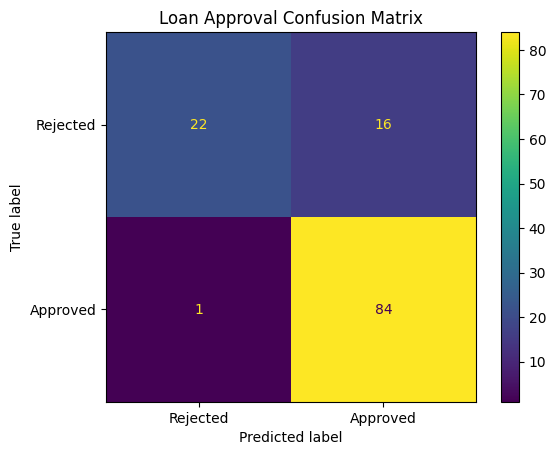

In [59]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
).plot()

plt.title("Loan Approval Confusion Matrix")
plt.show()


### Data Preprocessing

After examining the dataset, we identified numerical and categorical variables.

The preprocessing stage includes:

1. Removing the unnecessary `Loan_ID` identifier.
2. Handling missing numerical values using median imputation.
3. Handling missing categorical values using mode imputation.
4. Encoding categorical variables using One-Hot Encoding.
5. Scaling numerical features using StandardScaler.
6. Splitting the dataset into training (80%) and testing (20%) sets.

A preprocessing pipeline was implemented to ensure consistent data transformations before training the Logistic Regression model.

# Final Conclusion

## Project Results

The Logistic Regression model achieved an accuracy of **86.18%** on the test dataset.

The classification report showed:

- Class 0 (Rejected): Precision 96%, Recall 58%, F1-score 72%.
- Class 1 (Approved): Precision 84%, Recall 99%, F1-score 91%.

## Interpretation

The model performed particularly well in identifying approved loan applications.

However, its recall for rejected applications was lower, meaning that some rejected applications were incorrectly classified as approved.

This demonstrates why accuracy alone is not sufficient to evaluate a classification model.

## What I Learned

Through this project, I practiced:

- Exploratory Data Analysis.
- Missing value analysis and imputation.
- Data preprocessing.
- Categorical encoding.
- Feature scaling.
- Train-test splitting.
- Logistic Regression.
- Classification model evaluation.

## Final Conclusion

This project provided practical experience in developing a supervised Machine Learning classification model.

It also highlighted the importance of data quality, appropriate preprocessing techniques and evaluation metrics when building predictive models.

Further improvements could include cross-validation, feature engineering, hyperparameter tuning and testing other classification algorithms.